# Decision Tree – Heart Disease Risk Prediction

Part of the **Health Risk Assessment System** project (see the repository README).

**Task:** classify a person's heart-disease risk as **Low / Medium / High** from 28 lifestyle and health features.

**Pipeline (identical in every notebook of the project):**
1. Target = `pd.qcut(heart_disease_risk_score, 3)` → Low / Medium / High
2. Drop the five `*_risk_score` columns (data leakage)
3. One-hot encode the categorical columns
4. Stratified 80:20 split, `random_state=42`
5. `DecisionTreeClassifier(max_depth=10, random_state=42)`

**Before running:** upload `health_risk_predictor.csv` to Colab (left sidebar → Files → Upload) so it sits at `/content/health_risk_predictor.csv`.


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Files here:")
print(os.listdir())

Current folder: /content
Files here:
['.config', '.ipynb_checkpoints', '.csv', 'ML_Dataset.csv', 'sample_data']


In [ ]:
import pandas as pd
import numpy as np

# Dataset: upload health_risk_predictor.csv to Colab first (Files panel on the left)
df = pd.read_csv("/content/health_risk_predictor.csv")

print(df.head())

   Age  gender ethnicity education_level  income_level employment_status  \
0   58    Male     Asian      Highschool  Lower-Middle          Employed   
1   52  Female     White      Highschool        Middle          Employed   
2   60    Male  Hispanic      Highschool        Middle        Unemployed   
3   74  Female     Black      Highschool           Low           Retired   
4   46    Male     White        Graduate        Middle           Retired   

  smoking_status  alcohol_consumption_per_week  \
0          Never                             0   
1         Former                             1   
2          Never                             1   
3          Never                             0   
4          Never                             1   

   physical_activity_minutes_per_week  diet_score  ...  triglycerides  \
0                                 215         5.7  ...            145   
1                                 143         6.7  ...             30   
2                      

In [ ]:
df.shape

(97297, 33)

In [ ]:
df.columns

Index(['Age', 'gender', 'ethnicity', 'education_level', 'income_level',
       'employment_status', 'smoking_status', 'alcohol_consumption_per_week',
       'physical_activity_minutes_per_week', 'diet_score',
       'sleep_hours_per_day', 'screen_time_hours_per_day',
       'family_history_diabetes', 'hypertension_history',
       'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp',
       'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol',
       'ldl_cholesterol', 'triglycerides', 'glucose_fasting',
       'glucose_postprandial', 'insulin_level', 'hba1c', 'diabetes_risk_score',
       'hypertension_risk_score', 'heart_disease_risk_score',
       'obesity_risk_score', 'cholesterol_risk_score'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97297 entries, 0 to 97296
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 97297 non-null  int64  
 1   gender                              97297 non-null  object 
 2   ethnicity                           97297 non-null  object 
 3   education_level                     97297 non-null  object 
 4   income_level                        97297 non-null  object 
 5   employment_status                   97297 non-null  object 
 6   smoking_status                      97297 non-null  object 
 7   alcohol_consumption_per_week        97297 non-null  int64  
 8   physical_activity_minutes_per_week  97297 non-null  int64  
 9   diet_score                          97297 non-null  float64
 10  sleep_hours_per_day                 97297 non-null  float64
 11  screen_time_hours_per_day           97297

In [ ]:
df.isnull().sum()

,0
Age,0
gender,0
ethnicity,0
education_level,0
income_level,0
employment_status,0
smoking_status,0
alcohol_consumption_per_week,0
physical_activity_minutes_per_week,0
diet_score,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["HeartDiseaseClass"] = pd.qcut(
    df["heart_disease_risk_score"],
    q=3,
    labels=["Low","Medium","High"]
)

print(df["HeartDiseaseClass"].value_counts())


HeartDiseaseClass
High      32433
Low       32432
Medium    32432
Name: count, dtype: int64


In [ ]:
target = "HeartDiseaseClass"
leakage_columns = [
    "diabetes_risk_score",
    "hypertension_risk_score",
    "obesity_risk_score",
    "cholesterol_risk_score",
    "heart_disease_risk_score"
]
x = df.drop(columns=leakage_columns+[target])
y=df[target]


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [ ]:
categorical_cols= x.select_dtypes(include=["object","category"]).columns.tolist()
numerical_cols= x.select_dtypes(exclude=["object","category"]).columns.tolist()

print("Categorical columns:")
print(categorical_cols)
print("Numerical columns:")
print(numerical_cols)


Categorical columns:
['gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status']
Numerical columns:
['Age', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c']


#First split the data into training and testing sets and the encode them

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y # for maintaning a blance between test/train/validation dataset
    )
x_test.shape,x_train.shape,y_test.shape,y_train.shape

((19460, 28), (77837, 28), (19460,), (77837,))

#Now Encoding the Catagorical values to Numerical values
&

#Preprocessing

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_cols)
    ],
    remainder= "passthrough" # numerical values not encoded only categorical values
)

#Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_model = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",DecisionTreeClassifier(
        random_state=42,
        max_depth=10
        ))
])

dt_model.fit(x_train,y_train) # training the model

dt_pred = dt_model.predict(x_test) # testing the model


# The Graphical representation of your decision tree

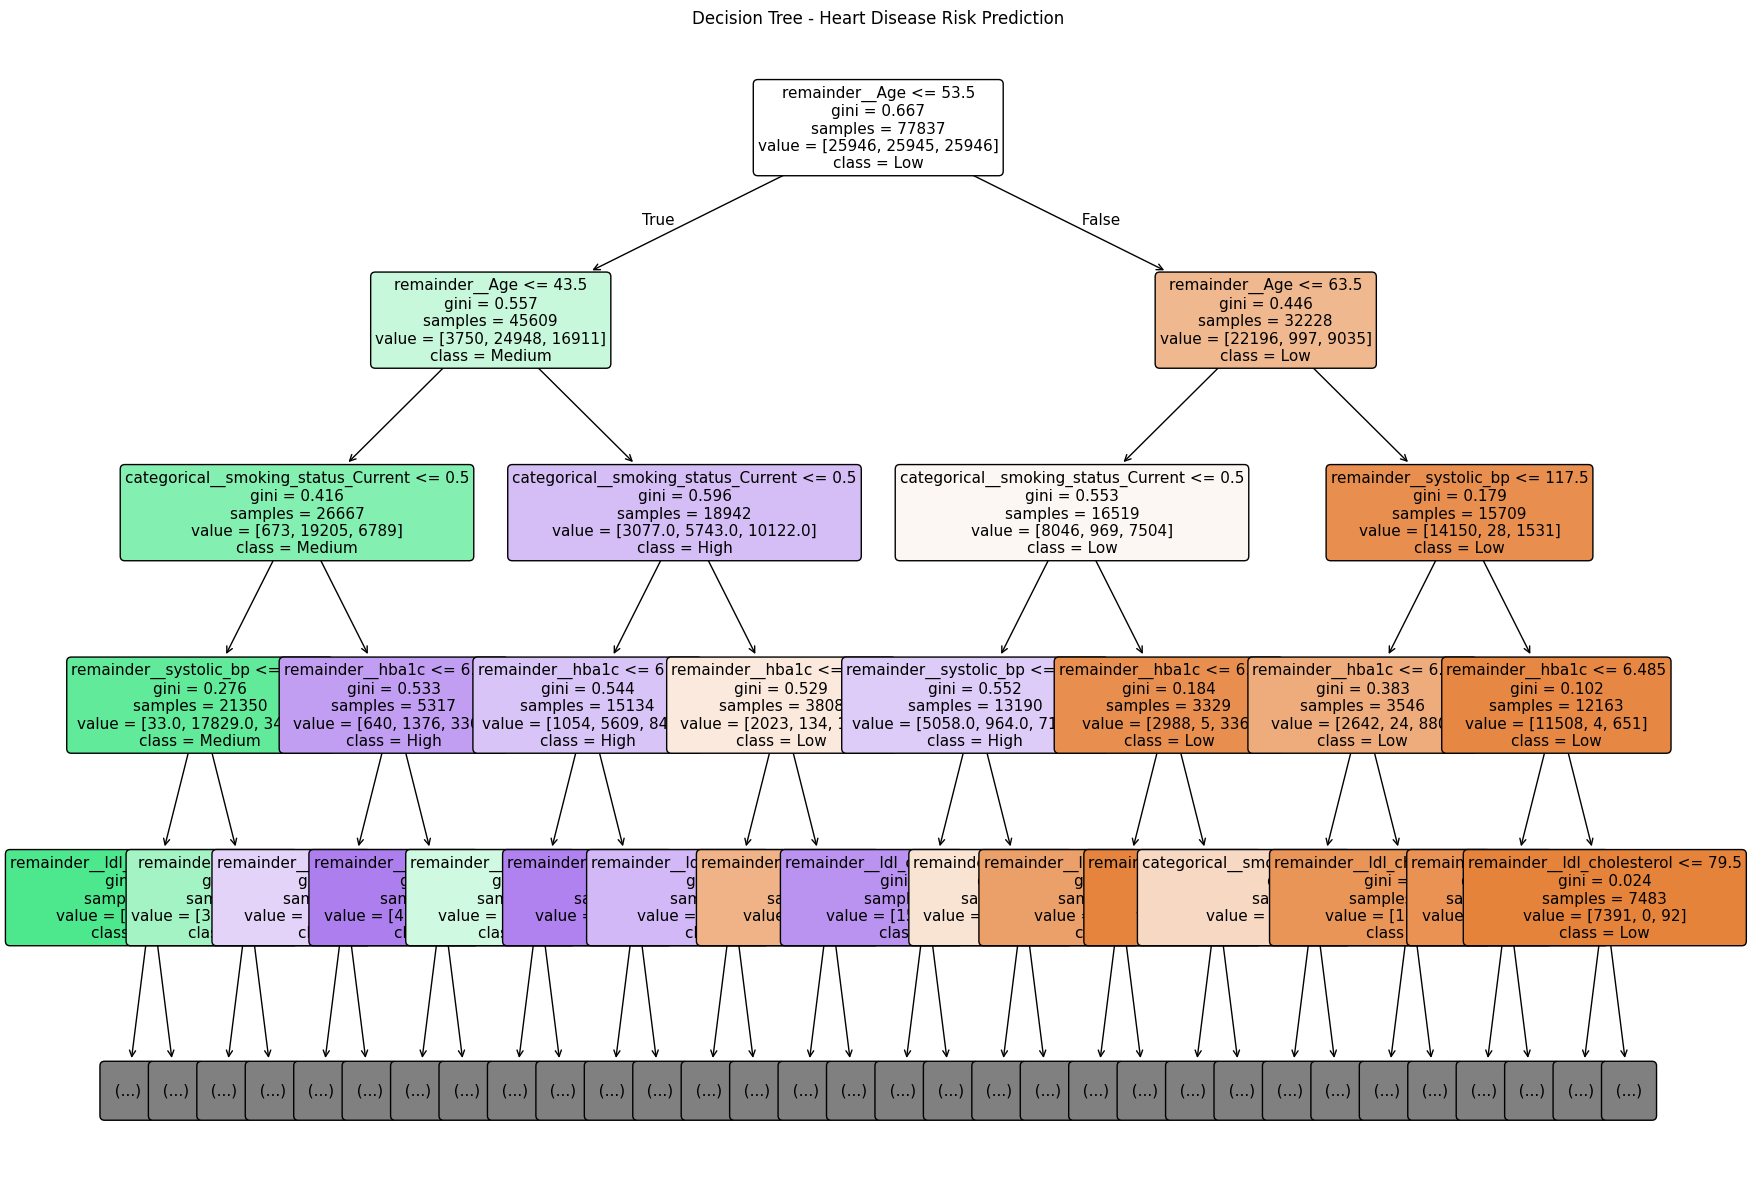

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree_model = dt_model.named_steps["classifier"]

feature_names = (
    dt_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

plt.figure(figsize=(20,15))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["Low","Medium","High"],
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=11
)
plt.title( "Decision Tree - Heart Disease Risk Prediction")
plt.show()

#Evaluate Decision Tree

Decision Tree
Accuracy: 0.8237410071942446
Precision: 0.8248202217902114
Recall: 0.8237410071942446
F1: 0.8241757599636966
              precision    recall  f1-score   support

        High       0.89      0.86      0.87      6487
         Low       0.86      0.87      0.86      6487
      Medium       0.73      0.75      0.74      6486

    accuracy                           0.82     19460
   macro avg       0.82      0.82      0.82     19460
weighted avg       0.82      0.82      0.82     19460



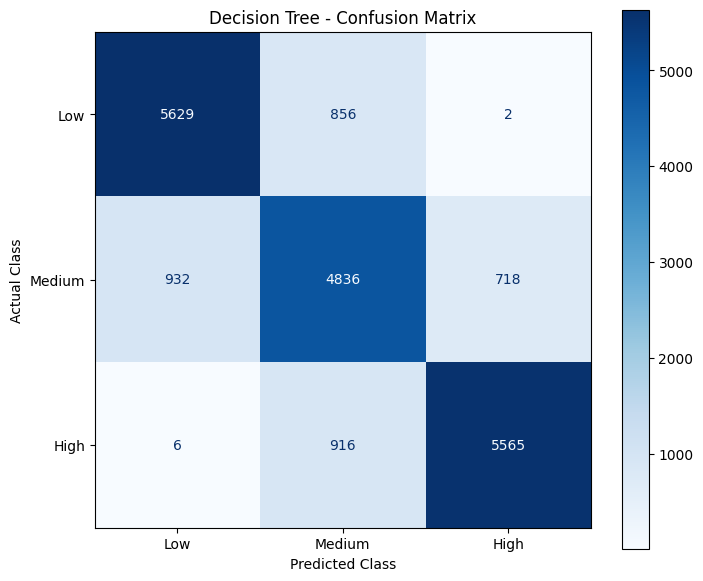

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Decision Tree")

print("Accuracy:",
      accuracy_score(y_test, dt_pred))

print("Precision:",
      precision_score(
          y_test,
          dt_pred,
          average="weighted"
      ))

print("Recall:",
      recall_score(
          y_test,
          dt_pred,
          average="weighted"
      ))

print("F1:",
      f1_score(
          y_test,
          dt_pred,
          average="weighted"
      ))

print(classification_report(y_test, dt_pred))

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    dt_pred,
    labels=["Low", "Medium", "High"]
)

# Display graphically
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

fig, ax = plt.subplots(figsize=(8, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [ ]:
# ---------- Predict for your own input (Decision Tree) ----------
new_person = {
    'Age': 45,
    'gender': 'Male',
    'ethnicity': 'Asian',
    'education_level': 'Graduate',
    'income_level': 'Middle',
    'employment_status': 'Employed',
    'smoking_status': 'Never',
    'alcohol_consumption_per_week': 1,
    'physical_activity_minutes_per_week': 150,
    'diet_score': 6.5,
    'sleep_hours_per_day': 7.0,
    'screen_time_hours_per_day': 5.0,
    'family_history_diabetes': 0,      # 0 = No, 1 = Yes
    'hypertension_history': 0,
    'cardiovascular_history': 0,
    'bmi': 24.5,
    'waist_to_hip_ratio': 0.88,
    'systolic_bp': 125,
    'diastolic_bp': 80,
    'heart_rate': 72,
    'cholesterol_total': 190,
    'hdl_cholesterol': 50,
    'ldl_cholesterol': 115,
    'triglycerides': 140,
    'glucose_fasting': 95,
    'glucose_postprandial': 140,
    'insulin_level': 8.0,
    'hba1c': 5.6,
}

# Check spelling of categorical values
for col in categorical_cols:
    assert new_person[col] in x[col].unique(), \
        f"Invalid value for {col}: '{new_person[col]}'. Allowed: {sorted(x[col].unique())}"

# One-row DataFrame in the same column order as training
new_df = pd.DataFrame([new_person])[x.columns]

# The pipeline handles encoding automatically
pred = dt_model.predict(new_df)[0]
probs = dt_model.predict_proba(new_df)[0]

print("Predicted Heart Disease Risk Class:", pred)
print("\nConfidence:")
for cls, p in zip(dt_model.classes_, probs):
    print(f"  {cls}: {p*100:.1f}%")

Predicted Heart Disease Risk Class: Medium

Confidence:
  High: 2.3%
  Low: 43.9%
  Medium: 53.8%
